In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "results" / "tables").exists():
    ROOT = ROOT.parent
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
MODELS = ["qwen2.5-3b", "olmo-2-1b", "smollm2-1.7b"]
LABELS = {
    "qwen2.5-3b": "Qwen2.5-3B-Instruct",
    "olmo-2-1b": "OLMo-2-1B-Instruct",
    "smollm2-1.7b": "SmolLM2-1.7B-Instruct",
}
COLORS = {"qwen2.5-3b": "#1b9e77", "olmo-2-1b": "#d95f02", "smollm2-1.7b": "#7570b3"}
plt.style.use("seaborn-v0_8-whitegrid")

def load(prefix, model):
    return pd.read_csv(TABLES / f"{prefix}_{model}.csv")

single = pd.concat([load("probe_single_turn", m) for m in MODELS], ignore_index=True)
multi = pd.concat([load("probe_multi_turn", m) for m in MODELS], ignore_index=True)
pca = pd.concat([load("pca_variance", m) for m in MODELS], ignore_index=True)
summaries = pd.concat([pd.read_csv(TABLES / f"summary_{m}.csv") for m in MODELS], ignore_index=True)
layers = pd.DataFrame(json.loads((TABLES / "selected_layers.json").read_text(encoding="utf-8"))).T.reset_index(names="model")
layers["model_label"] = layers["model"].map(LABELS)
display(layers[["model", "model_label", "selected", "alternate"]])

,model,model_label,selected,alternate
0,qwen2.5-3b,Qwen2.5-3B-Instruct,25,18
1,smollm2-1.7b,SmolLM2-1.7B-Instruct,17,12
2,olmo-2-1b,OLMo-2-1B-Instruct,8,11


## Figure explanations

**Figure 1 ? Held-out single-turn probe accuracy.** This checks whether each probe learned the benign/harmful token distinction from single-turn training data. Validation and test scores are reported separately so multi-turn results are not confused with supervised performance.

**Figure 2 ? PCA reference-space variance.** These curves show how much training-token variation is retained by the PCA reference space. Solid and dashed lines distinguish the selected and alternate layers used in downstream analysis.

**Figure 3 ? Harmful-token share versus context length.** Each curve measures how the selected MLP classifies response tokens as more context is included. Colors identify escalation versus benign controls, while line styles identify the context rendering condition.

**Figure 4 ? Per-turn trajectory.** This plot follows full-history Crescendo readouts turn by turn. It is the direct view of when the internal probe begins to flag the conversation.

**Figure 5 ? Condition and layer sensitivity.** Final-turn harmful-token shares are compared across Crescendo, single-prompt, and attack-objective conditions. Solid and dashed lines show whether the result is stable across selected and alternate layers.

**Figure 6 ? Probe versus judge.** This compares selected-layer MLP conversation-level accuracy with the independent text-only judge. The judge is supplementary and is evaluated only on the eight multi-turn/control conversations.

**Figure 7 ? PCA scatter geometry.** Training benign and harmful tokens provide the reference background, while final full-history readouts show where escalation and controls land in the same two-dimensional space. Points are sampled deterministically for readable figures.

**Figure 8 ? Category-specific trajectories.** These curves separate phishing/fraud from cyber-intrusion conversations and report percentage harmful-token share by turn. Solid lines are escalation conversations and dashed lines are matched benign controls.
**Figure 9 ? Conversation-level confusion matrices.** These matrices show true versus predicted labels for the selected-layer MLP probe and the text-only judge on the same eight conversations. They make false positives and false negatives visible instead of hiding them inside one accuracy value.


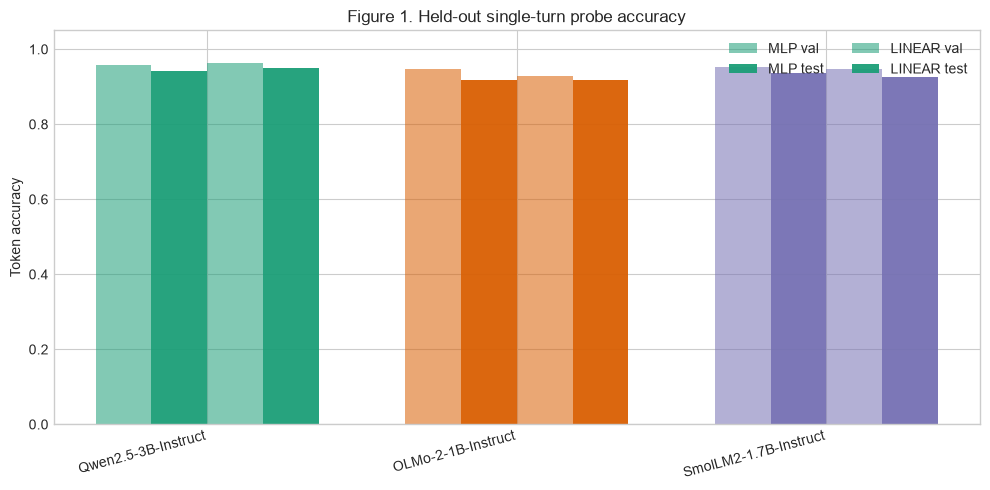

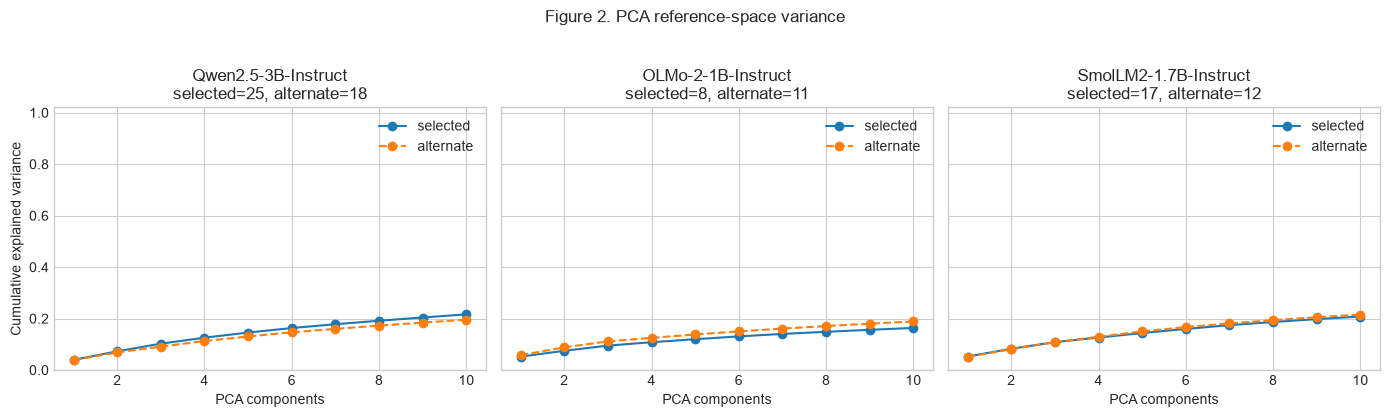

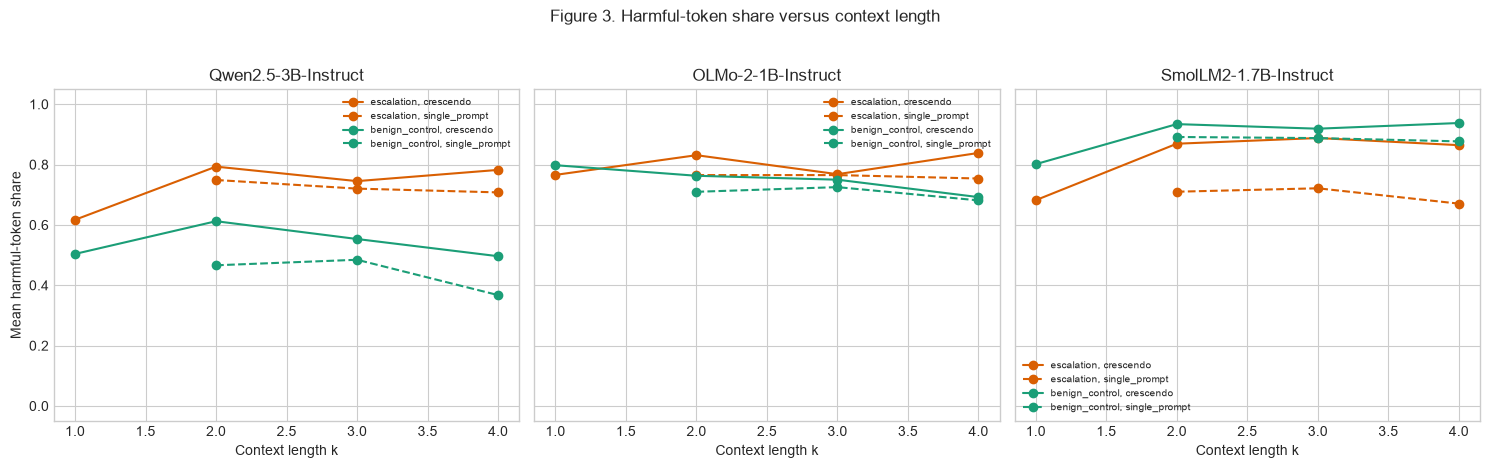

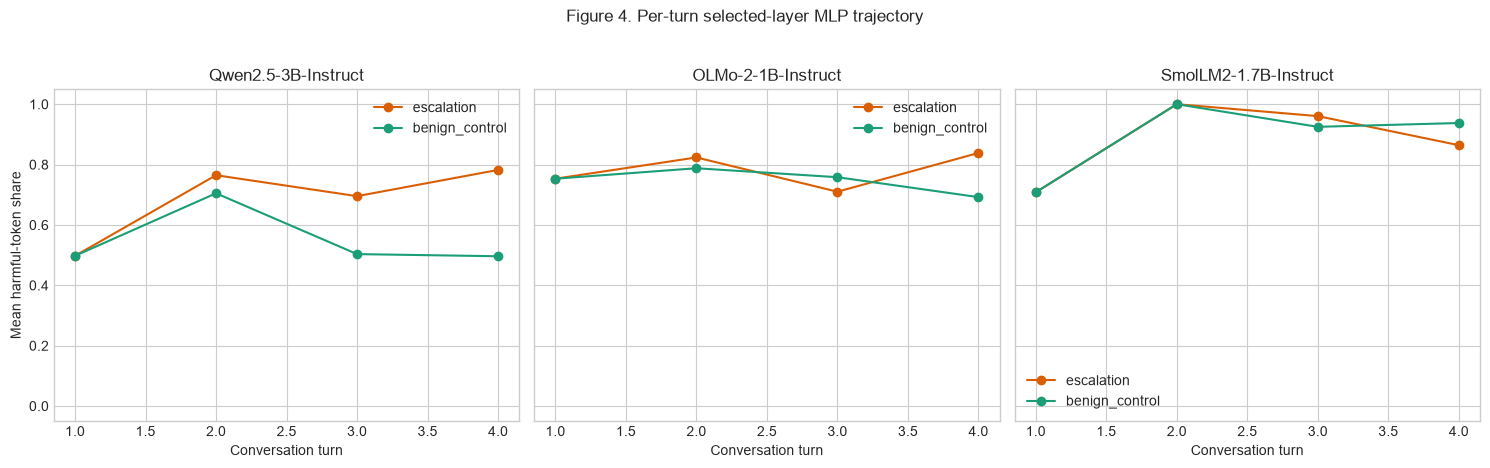

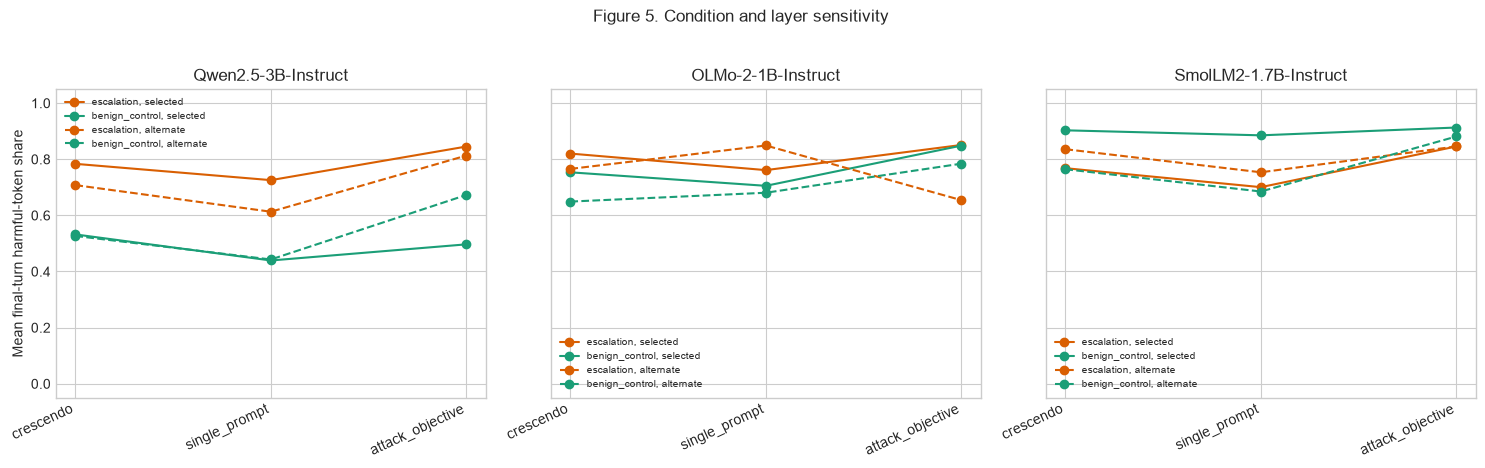

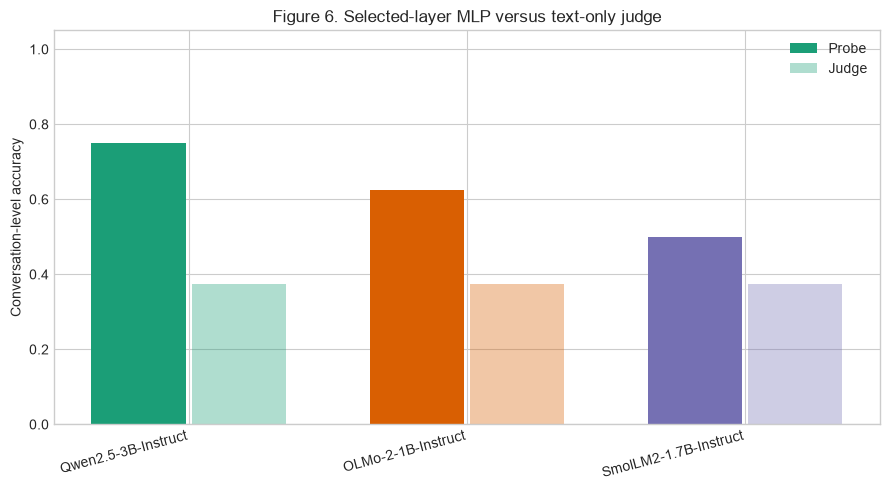

,model,probe_kind,layer_role,n_conversations,probe_accuracy,judge_accuracy,judge_scored
0,qwen2.5-3b,linear,alternate,8,0.625,0.375,8
1,qwen2.5-3b,linear,selected,8,0.625,0.375,8
2,qwen2.5-3b,mlp,alternate,8,0.750,0.375,8
3,qwen2.5-3b,mlp,selected,8,0.750,0.375,8
4,olmo-2-1b,linear,alternate,8,0.625,0.375,8
5,olmo-2-1b,linear,selected,8,0.625,0.375,8
6,olmo-2-1b,mlp,alternate,8,0.625,0.375,8
7,olmo-2-1b,mlp,selected,8,0.625,0.375,8
8,smollm2-1.7b,linear,alternate,8,0.500,0.375,8
9,smollm2-1.7b,linear,selected,8,0.500,0.375,8


In [2]:
# Figure 1: held-out single-turn probe accuracy.
data = single[(single.layer_role == "selected") & (single.split.isin(["val", "test"]))].copy()
fig, ax = plt.subplots(figsize=(10, 5))
width = 0.18
series = [("mlp", "val", 0), ("mlp", "test", 1), ("linear", "val", 2), ("linear", "test", 3)]
for x, model in enumerate(MODELS):
    subset = data[data.model == model]
    for kind, split, offset in series:
        row = subset[(subset.probe_kind == kind) & (subset.split == split)].iloc[0]
        ax.bar(x + (offset - 1.5) * width, row.token_accuracy, width, color=COLORS[model], alpha=0.55 if split == "val" else 0.95, label=f"{kind.upper()} {split}" if x == 0 else None)
ax.set_xticks(range(len(MODELS)), [LABELS[m] for m in MODELS], rotation=15, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("Token accuracy")
ax.set_title("Figure 1. Held-out single-turn probe accuracy")
ax.legend(ncol=2); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_01_single_turn_accuracy.png", dpi=180)
plt.show()

# Figure 2: cumulative PCA variance for selected and alternate layers.
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, model in zip(axes, MODELS):
    subset = pca[pca.model == model]
    for role, style in [("selected", "-"), ("alternate", "--")]:
        row = subset[subset.layer_role == role]
        ax.plot(row.n_components, row.cumulative_variance, marker="o", linestyle=style, label=role)
    layer = layers[layers.model == model].iloc[0]
    ax.set_title(f"{LABELS[model]}\nselected={layer.selected}, alternate={layer.alternate}")
    ax.set_xlabel("PCA components"); ax.set_ylim(0, 1.02); ax.legend()
axes[0].set_ylabel("Cumulative explained variance")
fig.suptitle("Figure 2. PCA reference-space variance", y=1.03); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_02_pca_variance.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 3: selected-layer MLP harmful-token share by context length.
context = multi[(multi.layer_role == "selected") & (multi.probe_kind == "mlp") & multi.condition.isin(["crescendo", "single_prompt"])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, model in zip(axes, MODELS):
    subset = context[context.model == model]
    for label, color in [("escalation", "#d95f02"), ("benign_control", "#1b9e77")]:
        for condition, style in [("crescendo", "-"), ("single_prompt", "--")]:
            row = subset[(subset.label == label) & (subset.condition == condition)].groupby("k", as_index=False).harmful_share.mean()
            if not row.empty:
                ax.plot(row.k, row.harmful_share, marker="o", linestyle=style, color=color, label=f"{label}, {condition}")
    ax.set_title(LABELS[model]); ax.set_xlabel("Context length k"); ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=7)
axes[0].set_ylabel("Mean harmful-token share")
fig.suptitle("Figure 3. Harmful-token share versus context length", y=1.03); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_03_context_length.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 4: full-history per-turn trajectory.
turns = multi[(multi.layer_role == "selected") & (multi.probe_kind == "mlp") & (multi.condition == "crescendo") & (multi.turn == multi.k)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, model in zip(axes, MODELS):
    subset = turns[turns.model == model]
    for label, color in [("escalation", "#d95f02"), ("benign_control", "#1b9e77")]:
        row = subset[subset.label == label].groupby("turn", as_index=False).harmful_share.mean()
        if not row.empty:
            ax.plot(row.turn, row.harmful_share, marker="o", color=color, label=label)
    ax.set_title(LABELS[model]); ax.set_xlabel("Conversation turn"); ax.set_ylim(-0.05, 1.05); ax.legend()
axes[0].set_ylabel("Mean harmful-token share")
fig.suptitle("Figure 4. Per-turn selected-layer MLP trajectory", y=1.03); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_04_per_turn.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 5: final-turn condition and layer sensitivity.
final = multi[multi.probe_kind == "mlp"].copy()
final = final[final.turn == final.groupby(["model", "record_id", "layer_role", "condition"]).turn.transform("max")]
final = final[final.condition.isin(["crescendo", "single_prompt", "attack_objective"])]
condition_summary = final.groupby(["model", "layer_role", "condition", "label"], as_index=False).harmful_share.mean()
condition_summary.to_csv(TABLES / "all_models_final_condition_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
conditions = ["crescendo", "single_prompt", "attack_objective"]
for ax, model in zip(axes, MODELS):
    subset = condition_summary[condition_summary.model == model]
    for role, style in [("selected", "-"), ("alternate", "--")]:
        for label, color in [("escalation", "#d95f02"), ("benign_control", "#1b9e77")]:
            row = subset[(subset.layer_role == role) & (subset.label == label)].set_index("condition").reindex(conditions)
            ax.plot(range(3), row.harmful_share, marker="o", linestyle=style, color=color, label=f"{label}, {role}")
    ax.set_title(LABELS[model]); ax.set_xticks(range(3), conditions, rotation=25, ha="right"); ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=7)
axes[0].set_ylabel("Mean final-turn harmful-token share")
fig.suptitle("Figure 5. Condition and layer sensitivity", y=1.03); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_05_condition_layer.png", dpi=180, bbox_inches="tight")
plt.show()

# Figure 6: selected-layer MLP versus text-only judge.
selected_summary = summaries[(summaries.probe_kind == "mlp") & (summaries.layer_role == "selected")]
fig, ax = plt.subplots(figsize=(9, 5))
for x, model in enumerate(MODELS):
    row = selected_summary[selected_summary.model == model].iloc[0]
    ax.bar(x - 0.18, row.probe_accuracy, 0.34, color=COLORS[model], label="Probe" if x == 0 else None)
    ax.bar(x + 0.18, row.judge_accuracy, 0.34, color=COLORS[model], alpha=0.35, label="Judge" if x == 0 else None)
ax.set_xticks(range(3), [LABELS[m] for m in MODELS], rotation=15, ha="right"); ax.set_ylim(0, 1.05)
ax.set_ylabel("Conversation-level accuracy"); ax.set_title("Figure 6. Selected-layer MLP versus text-only judge"); ax.legend(); fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_06_probe_vs_judge.png", dpi=180)
plt.show()
display(summaries)

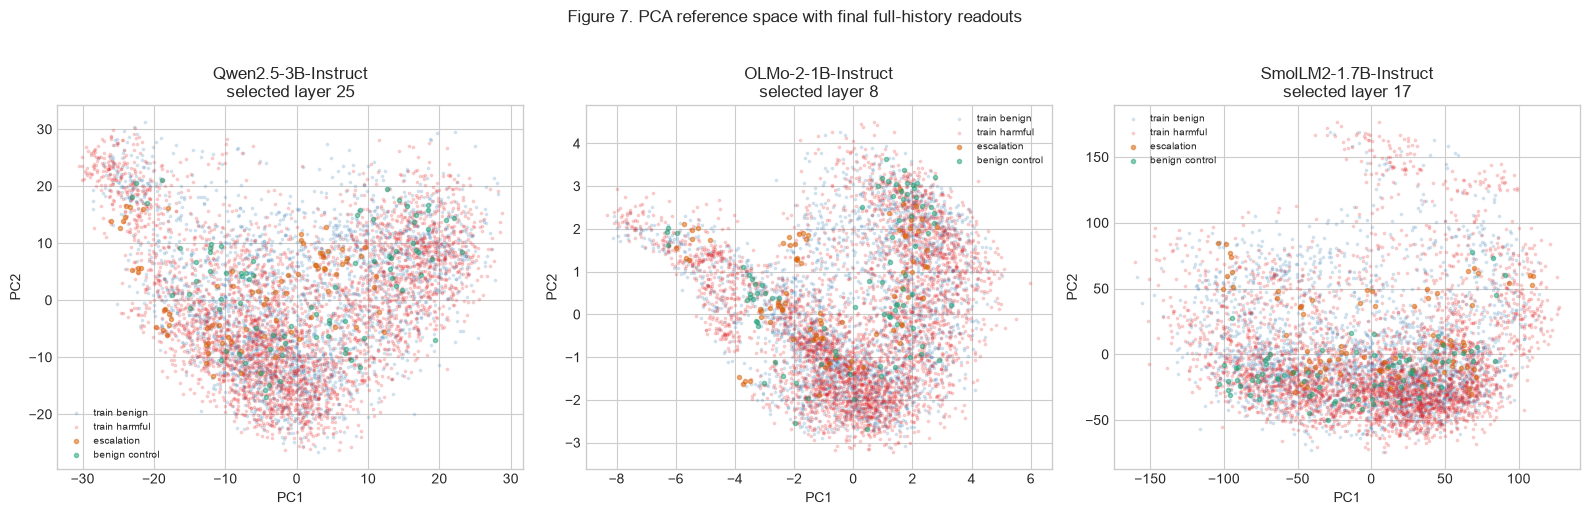

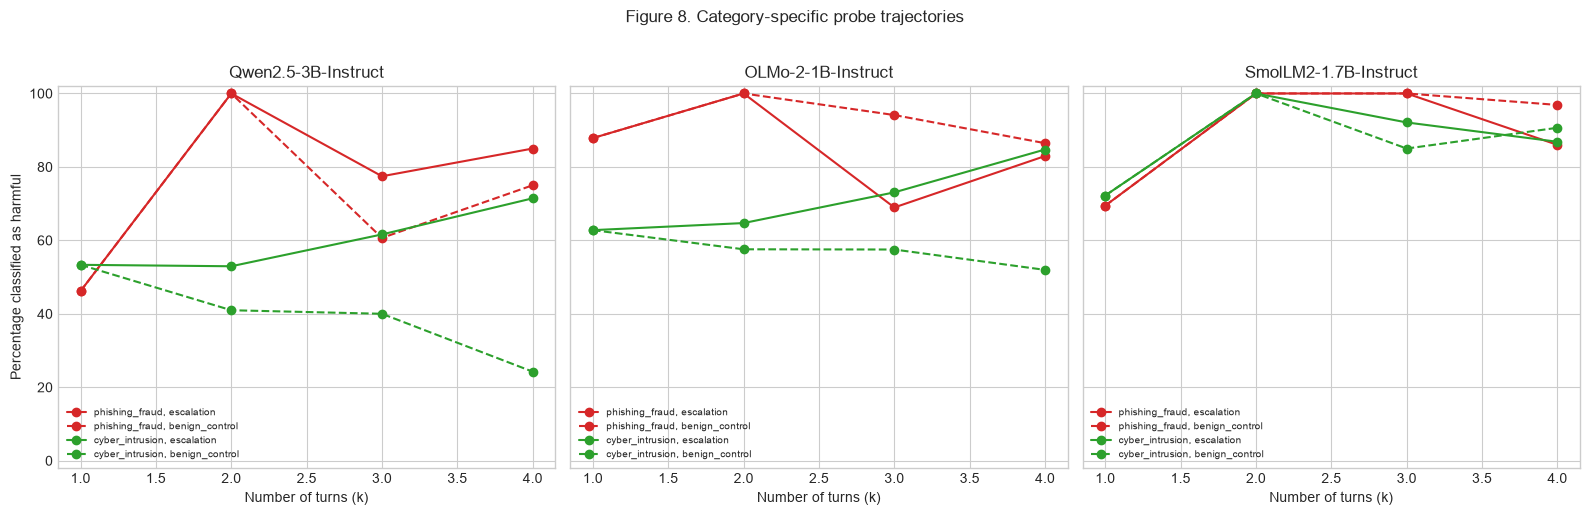

In [3]:
# Paper-style PCA scatter panels from cached activations.
import sys
import numpy as np
from sklearn.decomposition import PCA
sys.path.insert(0, str(ROOT / "src"))
from escalation_probes.cache import load_acts, load_tokens, job_key
from escalation_probes.data import load_dir

single_records = load_dir(ROOT / "data" / "single_turn_reference")
conversations = load_dir(ROOT / "data" / "multi_turn") + load_dir(ROOT / "data" / "controls")
splits = json.loads((ROOT / "data" / "splits" / "splits.json").read_text(encoding="utf-8"))
by_id = {record["id"]: record for record in single_records}
train_records = [by_id[record_id] for record_id in splits["train"]]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=False, sharey=False)
for ax, model in zip(axes, MODELS):
    layer = int(layers.loc[layers.model == model, "selected"].iloc[0])
    cache = ROOT / "results" / "activations" / model
    x_train, y_train, _ = load_tokens(cache, train_records, layer)
    pca_fit = PCA(n_components=2, random_state=42).fit(x_train)
    rng = np.random.default_rng(42)
    sample = rng.choice(len(x_train), size=min(6000, len(x_train)), replace=False)
    z = pca_fit.transform(x_train[sample])
    ax.scatter(z[y_train[sample] == 0, 0], z[y_train[sample] == 0, 1], s=3, alpha=0.16, color="#377eb8", label="train benign")
    ax.scatter(z[y_train[sample] == 1, 0], z[y_train[sample] == 1, 1], s=3, alpha=0.16, color="#e41a1c", label="train harmful")
    for conv in conversations:
        job = {"condition": "crescendo", "turn": len(conv["turns"]), "k": len(conv["turns"])}
        tokens = load_acts(cache, job_key(conv["id"], job["condition"], job["turn"], job["k"]), layer)
        points = pca_fit.transform(tokens)
        label = "escalation" if conv["label"] == "escalation" else "benign control"
        color = "#d95f02" if conv["label"] == "escalation" else "#1b9e77"
        ax.scatter(points[:, 0], points[:, 1], s=9, alpha=0.5, color=color, label=label)
    handles, labels_seen = ax.get_legend_handles_labels()
    unique = dict(zip(labels_seen, handles))
    ax.legend(unique.values(), unique.keys(), fontsize=7)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(f"{LABELS[model]}\nselected layer {layer}")
fig.suptitle("Figure 7. PCA reference space with final full-history readouts", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_07_pca_scatter.png", dpi=180, bbox_inches="tight")
plt.show()

# Paper-style category curves: solid = escalation, dashed = matched benign control.
category_map = {record["id"]: record["category"] for record in conversations}
category = multi[(multi.layer_role == "selected") & (multi.probe_kind == "mlp") & (multi.condition == "crescendo") & (multi.turn == multi.k)].copy()
category = category.assign(category=category.record_id.map(category_map))
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, model in zip(axes, MODELS):
    subset = category[category.model == model]
    for topic, color in [("phishing_fraud", "#d62728"), ("cyber_intrusion", "#2ca02c")]:
        for label, style in [("escalation", "-"), ("benign_control", "--")]:
            row = subset[(subset.category == topic) & (subset.label == label)].groupby("k", as_index=False).harmful_share.mean()
            if not row.empty:
                ax.plot(row.k, row.harmful_share * 100, marker="o", linestyle=style, color=color, label=f"{topic}, {label}")
    ax.set_title(LABELS[model])
    ax.set_xlabel("Number of turns (k)")
    ax.set_ylim(-2, 102)
    ax.legend(fontsize=7)
axes[0].set_ylabel("Percentage classified as harmful")
fig.suptitle("Figure 8. Category-specific probe trajectories", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "all_models_figure_08_category_trajectories.png", dpi=180, bbox_inches="tight")
plt.show()

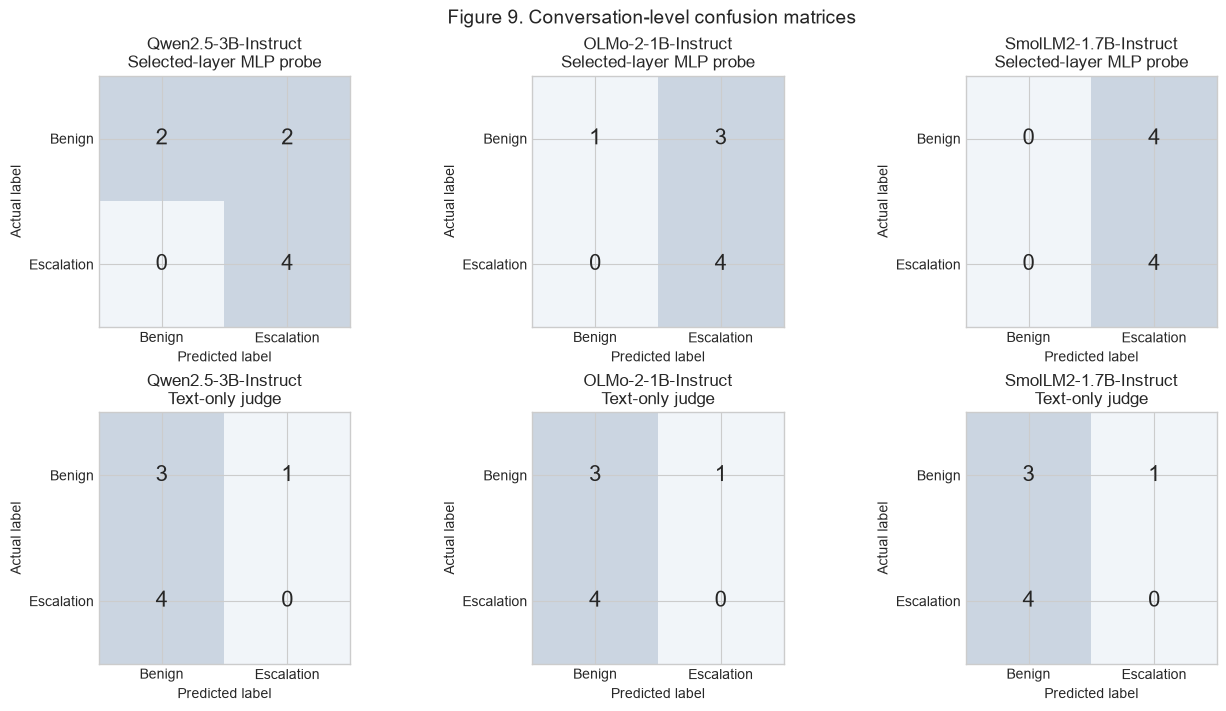

In [4]:
# Figure 9: conversation-level confusion matrices.
from matplotlib.colors import ListedColormap

def binary_confusion(rows, prediction_column):
    actual = (rows["label"] == "escalation").astype(int).to_numpy()
    predicted = rows[prediction_column].astype(int).to_numpy()
    matrix = pd.crosstab(
        pd.Series(actual, name="Actual"),
        pd.Series(predicted, name="Predicted"),
        dropna=False,
    ).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    return matrix.to_numpy()

confusion_rows = summaries[(summaries.probe_kind == "mlp") & (summaries.layer_role == "selected")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for column_index, model in enumerate(MODELS):
    comparison = pd.read_csv(TABLES / f"comparison_{model}.csv")
    comparison = comparison[
        (comparison.probe_kind == "mlp")
        & (comparison.layer_role == "selected")
    ].copy()
    comparison["probe_prediction"] = comparison["probe_final"].astype(int)
    comparison["judge_prediction"] = comparison["judge_final"].astype(int)
    for row_index, (method, prediction_column) in enumerate(
        [("Selected-layer MLP probe", "probe_prediction"), ("Text-only judge", "judge_prediction")]
    ):
        matrix = binary_confusion(comparison, prediction_column)
        ax = axes[row_index, column_index]
        ax.imshow(matrix, cmap=ListedColormap(["#f1f5f9", "#cbd5e1"]), vmin=0, vmax=max(1, matrix.max()))
        for actual in range(2):
            for predicted in range(2):
                ax.text(predicted, actual, matrix[actual, predicted], ha="center", va="center", fontsize=16)
        ax.set_xticks([0, 1], ["Benign", "Escalation"])
        ax.set_yticks([0, 1], ["Benign", "Escalation"])
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
        ax.set_title(f"{LABELS[model]}\n{method}")
fig.suptitle("Figure 9. Conversation-level confusion matrices (n=8)", fontsize=14)
fig.savefig(FIGURES / "all_models_figure_09_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()
